## Lab 5: Recap on Dimensionality Reduction Techniques

In this lab we apply all the dimensionality reduction techniques seen so far (PCA, Kernel PCA, Isomap) plus t-SNE, UMAP and the autoencoder to the same dataset, and we compare them.

You are required to use **your own implementations** of PCA, Kernel PCA and Isomap from the previous labs, and to write **your own autoencoder** with the layers of `pytorch`. For t-SNE and UMAP you can use external libraries.

The first part of this notebook (download and preprocessing of the dataset) is already written for you: run it, do not modify it, and write your solution below.

In [1]:
import os
import gzip
import struct
import urllib.request

import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

import warnings
warnings.filterwarnings('ignore')

np.random.seed(0)

# Exercise 1
### Download the dataset
The `Fashion-MNIST` dataset ([link](https://github.com/zalandoresearch/fashion-mnist#get-the-data)) is made of $28\times28$ grayscale images of clothes, belonging to 10 classes. The four files are downloaded in `../Datasets/fashion_mnist` (only the first time you run the notebook).

In [2]:
DATA_DIR = "../Datasets/fashion_mnist"
BASE_URL = "https://raw.githubusercontent.com/zalandoresearch/fashion-mnist/master/data/fashion/"
FILES = ["train-images-idx3-ubyte.gz", "train-labels-idx1-ubyte.gz",
         "t10k-images-idx3-ubyte.gz", "t10k-labels-idx1-ubyte.gz"]

os.makedirs(DATA_DIR, exist_ok=True)
for f in FILES:
    path = os.path.join(DATA_DIR, f)
    if not os.path.exists(path):
        print("downloading", f)
        urllib.request.urlretrieve(BASE_URL + f, path)   # if this fails, download the 4 files by hand from the link above
print("files in", DATA_DIR, ":", sorted(os.listdir(DATA_DIR)))

downloading train-images-idx3-ubyte.gz
downloading train-labels-idx1-ubyte.gz
downloading t10k-images-idx3-ubyte.gz
downloading t10k-labels-idx1-ubyte.gz
files in ../Datasets/fashion_mnist : ['t10k-images-idx3-ubyte.gz', 't10k-labels-idx1-ubyte.gz', 'train-images-idx3-ubyte.gz', 'train-labels-idx1-ubyte.gz']


In [3]:
def read_idx(filename):
    """Read a file in the IDX format (used by MNIST-like datasets)."""
    with gzip.open(filename, 'rb') as f:
        zero, data_type, dims = struct.unpack('>HBB', f.read(4))
        shape = tuple(struct.unpack('>I', f.read(4))[0] for d in range(dims))
        return np.frombuffer(f.read(), dtype=np.uint8).reshape(shape)

Xtrain_full = read_idx(os.path.join(DATA_DIR, 'train-images-idx3-ubyte.gz'))
ytrain_full = read_idx(os.path.join(DATA_DIR, 'train-labels-idx1-ubyte.gz'))
Xtest_full  = read_idx(os.path.join(DATA_DIR, 't10k-images-idx3-ubyte.gz'))
ytest_full  = read_idx(os.path.join(DATA_DIR, 't10k-labels-idx1-ubyte.gz'))

print(Xtrain_full.shape, ytrain_full.shape, Xtest_full.shape, ytest_full.shape)

(60000, 28, 28) (60000,) (10000, 28, 28) (10000,)


In [4]:
labels_dict = {0: 'T-shirt/top', 1: 'Trouser', 2: 'Pullover', 3: 'Dress', 4: 'Coat',
               5: 'Sandal', 6: 'Shirt', 7: 'Sneaker', 8: 'Bag', 9: 'Ankle boot'}

### Preprocessing
1. **Undersampling**: 5000 images for training and 1000 for testing (random, stratified, so that all classes are equally represented). Some algorithms (kernel PCA, Isomap, t-SNE) need the $n\times n$ matrix of the pairwise relations, and they would be too slow on 60000 points.
2. **Rescaling** of the pixels to $[0,1]$.
3. **Centering**: we subtract the mean image of the *training set* from both the training and the test set (the test set must not be used to compute any statistic).
4. **Flattening**: every image becomes a vector of $784$ pixels (the format needed by all the algorithms of today).

In [5]:
Xtrain_img, _, ytrain, _ = train_test_split(Xtrain_full, ytrain_full, train_size=5000, stratify=ytrain_full, random_state=0)
_, Xtest_img, _, ytest   = train_test_split(Xtest_full, ytest_full, test_size=1000, stratify=ytest_full, random_state=0)

# rescale to [0, 1]
Xtrain_img = Xtrain_img / 255
Xtest_img = Xtest_img / 255

# center with the mean of the TRAIN set
mean_img = Xtrain_img.mean(axis=0)            # (28, 28), useful to visualize the images after the centering
Xtrain = Xtrain_img - mean_img
Xtest = Xtest_img - mean_img

# flatten: (n, 28, 28) -> (n, 784)
Xtrain = Xtrain.reshape(Xtrain.shape[0], -1)
Xtest = Xtest.reshape(Xtest.shape[0], -1)

print("Xtrain:", Xtrain.shape, " Xtest:", Xtest.shape)
print("mean of the train pixels (should be ~0):", Xtrain.mean().round(6))
print("class counts in train:", np.bincount(ytrain))

Xtrain: (5000, 784)  Xtest: (1000, 784)
mean of the train pixels (should be ~0): -0.0
class counts in train: [500 500 500 500 500 500 500 500 500 500]


The variables you will work with are `Xtrain` ($5000\times784$) and `Xtest` ($1000\times784$), with the labels `ytrain` and `ytest` (use the labels **only** for the colours of the plots and for the evaluation of the results, never to compute the embeddings). The dictionary `labels_dict` gives the name of each class, and `mean_img` can be added back to a reshaped image (`x.reshape(28, 28) + mean_img`) to display it in its original colors.

Let us have a look at the data.

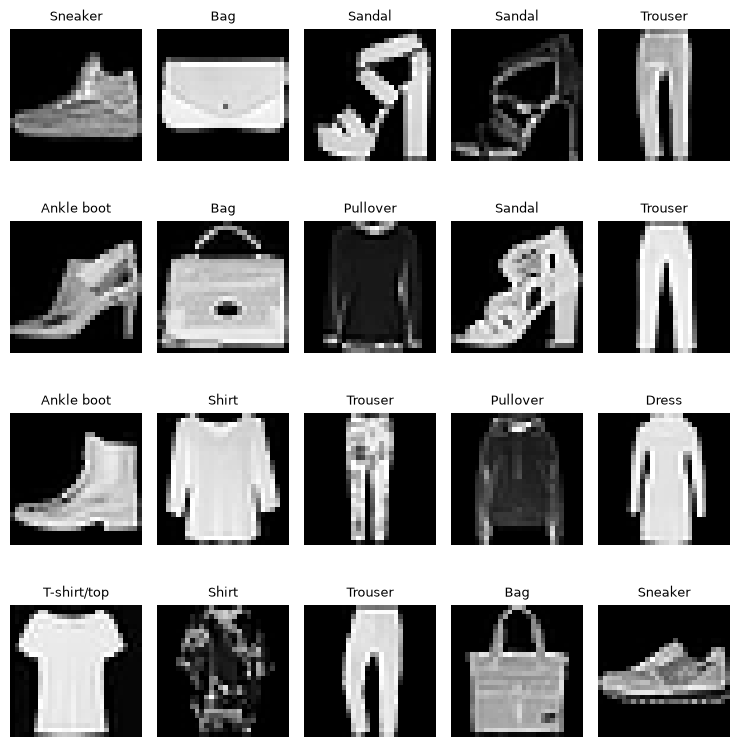

In [6]:
n_row, n_col = 4, 5
fig, ax = plt.subplots(n_row, n_col, figsize=(1.5*n_col, 2*n_row))
for i in range(n_row * n_col):
    ax_ = ax[i // n_col, i % n_col]
    ax_.imshow(Xtrain_img[i], cmap='gray')
    ax_.set_title(labels_dict[ytrain[i]], fontsize=9)
    ax_.axis('off')
plt.tight_layout()
plt.show()

# Solution
### Helper functions
`plot_embedding` draws the first two (and three, if available) components coloured by class. `evaluate` gives two numbers for each embedding, used in the final comparison:
- **kNN accuracy**: 5-fold cross-validated accuracy of a 10-nearest-neighbours classifier in the 2-dimensional embedding (how well the classes are separated). Note that the embeddings of all the methods are computed on the whole training set, so this is a *comparison* between methods, not an estimate of the generalization error (see the bonus for the test set).
- **Trustworthiness** (`sklearn.manifold.trustworthiness`, between 0 and 1): how many of the 10 nearest neighbours of a point in the embedding were also close to it in the original 784-dimensional space (how much the *local structure* is preserved).

All the embeddings are compared in 2 dimensions.

In [7]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import cross_val_score
from sklearn.manifold import trustworthiness
import pandas as pd
import time

def plot_embedding(Z, title, three_d=True):
    """First two (and three) components of the embedding Z, coloured by class."""
    three_d = three_d and Z.shape[1] >= 3
    fig = plt.figure(figsize=(16, 7) if three_d else (8.5, 7))
    fig.suptitle(title, fontsize=16)
    cmap = plt.get_cmap('tab10', 10)
    ax = fig.add_subplot(1, 2 if three_d else 1, 1)
    p = ax.scatter(Z[:, 0], Z[:, 1], c=ytrain, s=6, cmap=cmap, vmin=-0.5, vmax=9.5)
    ax.set_xlabel("component 1"); ax.set_ylabel("component 2")
    if three_d:
        ax = fig.add_subplot(1, 2, 2, projection='3d')
        p = ax.scatter3D(Z[:, 0], Z[:, 1], Z[:, 2], c=ytrain, s=6, cmap=cmap, vmin=-0.5, vmax=9.5)
        ax.set_xlabel("component 1"); ax.set_ylabel("component 2"); ax.set_zlabel("component 3")
    cb = fig.colorbar(p, ax=fig.axes, ticks=range(10), pad=0.02)
    cb.ax.set_yticklabels([labels_dict[i] for i in range(10)])
    plt.show()

results = []
def evaluate(method, params, Z):
    """Store kNN accuracy and trustworthiness of the first two components of Z."""
    Z2 = Z[:, :2]
    acc = cross_val_score(KNeighborsClassifier(10), Z2, ytrain, cv=5).mean()
    tw = trustworthiness(Xtrain, Z2, n_neighbors=10)
    results.append(dict(method=method, params=params, knn_acc=round(acc, 3), trustworthiness=round(tw, 3)))
    print(f"{method:12s} {params:28s} kNN accuracy {acc:.3f}   trustworthiness {tw:.3f}")

### PCA (own implementation)
Eigendecomposition of the covariance matrix $C=\frac1n X^TX$ (the data are already centered).

matches sklearn (eigenvalues): True


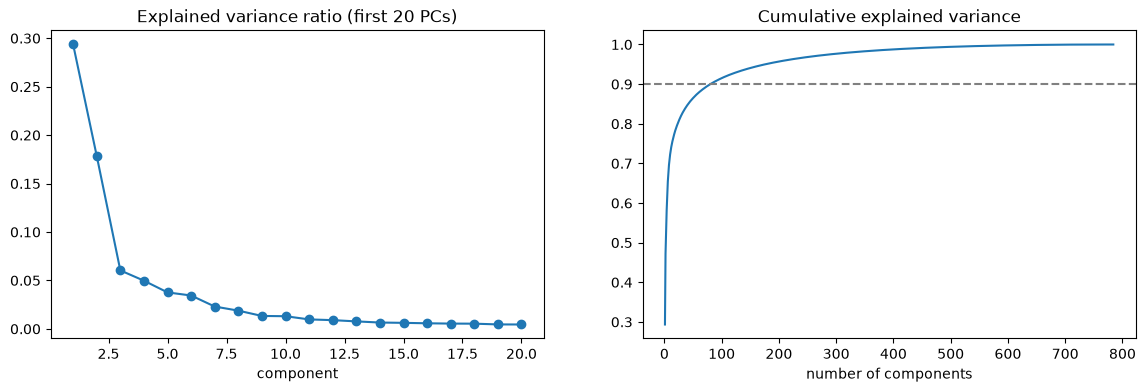

  2 PCs explain 0.472 of the variance
  3 PCs explain 0.532 of the variance
 10 PCs explain 0.722 of the variance
 50 PCs explain 0.865 of the variance
100 PCs explain 0.915 of the variance
PCs needed for 90% of the variance: 81


In [8]:
def my_pca(X):
    """PCA via eigh on the covariance matrix. X must be centered. Returns eigenvalues (desc.) and eigenvectors (columns)."""
    C = X.T @ X / X.shape[0]
    w, V = np.linalg.eigh(C)
    idx = np.argsort(w)[::-1]
    return w[idx], V[:, idx]

eigvals, eigvecs = my_pca(Xtrain)
X_pca = Xtrain @ eigvecs

from sklearn.decomposition import PCA
pca_sk = PCA().fit(Xtrain)
print("matches sklearn (eigenvalues):", np.allclose(eigvals, pca_sk.explained_variance_ * (len(Xtrain) - 1) / len(Xtrain)))

ratio = eigvals / eigvals.sum()
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
ax[0].plot(range(1, 21), ratio[:20], "o-"); ax[0].set_title("Explained variance ratio (first 20 PCs)"); ax[0].set_xlabel("component")
ax[1].plot(range(1, 785), np.cumsum(ratio)); ax[1].set_title("Cumulative explained variance"); ax[1].set_xlabel("number of components")
ax[1].axhline(0.9, color="gray", ls="--")
plt.show()
for d in (2, 3, 10, 50, 100):
    print(f"{d:3d} PCs explain {ratio[:d].sum():.3f} of the variance")
print("PCs needed for 90% of the variance:", int(np.searchsorted(np.cumsum(ratio), 0.9)) + 1)

**Comment.** The spectrum decays slowly: 2 PCs explain only 47% of the variance, 10 PCs 72%, and 81 PCs (out of 784) are needed to reach 90%. A 2-dimensional projection necessarily throws away a lot of information.

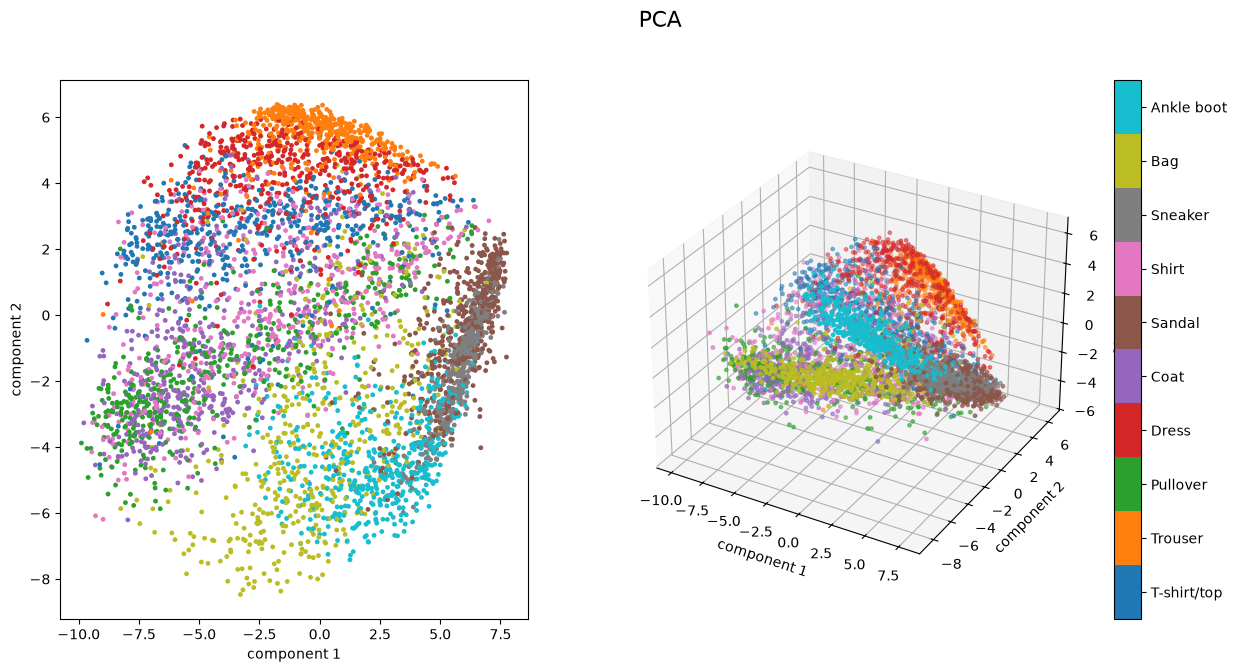

PCA          2 PCs                        kNN accuracy 0.534   trustworthiness 0.914


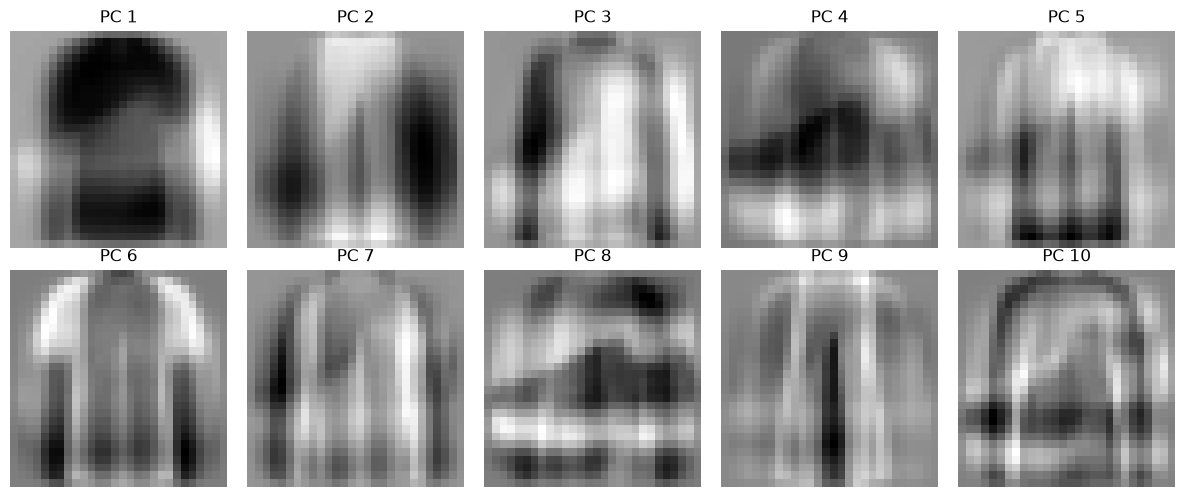

In [9]:
plot_embedding(X_pca, "PCA")
evaluate("PCA", "2 PCs", X_pca)

fig, axes = plt.subplots(2, 5, figsize=(12, 5))
for i, ax in enumerate(axes.ravel()):
    ax.imshow(eigvecs[:, i].reshape(28, 28), cmap="gray"); ax.set_title(f"PC {i+1}"); ax.axis("off")
plt.tight_layout(); plt.show()

**Comment.** In 2D the PCA places the classes along a few directions (trousers and dresses at the top, sandals and sneakers on the right, bags and ankle boots at the bottom), but the four upper-body classes (T-shirt, pullover, coat, shirt) overlap almost completely: kNN accuracy $0.53$, trustworthiness $0.91$. The principal components, seen as images, are "eigen-clothes": PC 1 is a garment-shaped template (silhouette of a top against the regions where footwear and trousers live), and the following ones add sleeves, collar and legs as corrections.

### Kernel PCA (own implementation)
Gram matrix $K_{ij}=k(x_i,x_j)$, centered in feature space ($\tilde K = K - \mathbf 1_n K - K\mathbf 1_n + \mathbf 1_n K\mathbf 1_n$), top eigenpairs $(\lambda_j,v_j)$ of $\tilde K$, projections $\sqrt{\lambda_j}\,v_j$. Kernels: Gaussian $k(x,x')=\exp(-\|x-x'\|^2/2\sigma^2)$ and polynomial $k(x,x')=(1+x^Tx')^\delta$.

In [10]:
from scipy.sparse.linalg import eigsh
from scipy.spatial.distance import cdist

def gaussian_kernel(A, B, sigma):
    return np.exp(-cdist(A, B, "sqeuclidean") / (2 * sigma**2))

def poly_kernel(A, B, delta):
    return (1 + A @ B.T) ** delta

def center_kernel(K):
    return K - K.mean(axis=0, keepdims=True) - K.mean(axis=1, keepdims=True) + K.mean()

def my_kpca(K, n_components=3):
    """Kernel PCA from a Gram matrix K. Returns the projections of the training points, the eigenvalues and the eigenvectors."""
    w, V = eigsh(center_kernel(K), k=n_components, which="LA")
    idx = np.argsort(w)[::-1]
    w, V = w[idx], V[:, idx]
    return V * np.sqrt(np.maximum(w, 0)), w, V

# sanity check against sklearn (components are defined up to a sign)
from sklearn.decomposition import KernelPCA
Z, _, _ = my_kpca(gaussian_kernel(Xtrain, Xtrain, 7.0), 3)
Z_sk = KernelPCA(3, kernel="rbf", gamma=1 / (2 * 7.0**2)).fit_transform(Xtrain)
print("Gaussian, sigma=7 | max abs diff:", [float(min(np.abs(Z[:, j] - s * Z_sk[:, j]).max() for s in (1, -1))) for j in range(3)])
Z, _, _ = my_kpca(poly_kernel(Xtrain, Xtrain, 2), 3)
Z_sk = KernelPCA(3, kernel="poly", degree=2, gamma=1, coef0=1).fit_transform(Xtrain)
print("Poly, delta=2     | max abs diff:", [float(min(np.abs(Z[:, j] - s * Z_sk[:, j]).max() for s in (1, -1))) for j in range(3)])

d2 = cdist(Xtrain[:1000], Xtrain[:1000])
print("typical distance between two images (median):", np.median(d2[np.triu_indices(1000, 1)]).round(2))

Gaussian, sigma=7 | max abs diff: [2.1094237467877974e-15, 1.5543122344752192e-15, 1.7763568394002505e-15]
Poly, delta=2     | max abs diff: [3.126388037344441e-13, 3.304023721284466e-13, 3.33510996597397e-13]
typical distance between two images (median): 11.47


The typical distance between two images gives the scale for $\sigma$: if $\sigma$ is much smaller than that, every point is similar only to itself (the Gram matrix is close to the identity), if it is much larger the kernel is almost constant.

kPCA Gauss   sigma=1                      kNN accuracy 0.225   trustworthiness 0.579
kPCA Gauss   sigma=2                      kNN accuracy 0.419   trustworthiness 0.724
kPCA Gauss   sigma=5                      kNN accuracy 0.530   trustworthiness 0.897
kPCA Gauss   sigma=7                      kNN accuracy 0.536   trustworthiness 0.907
kPCA Gauss   sigma=10                     kNN accuracy 0.526   trustworthiness 0.912


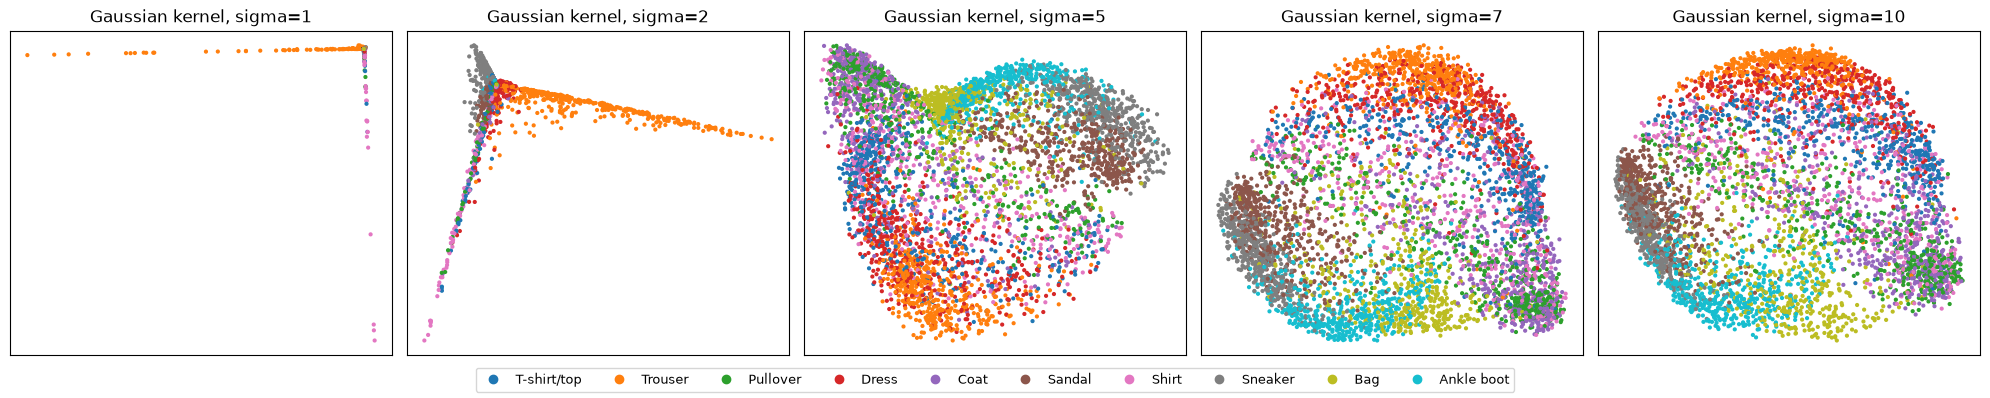

In [11]:
def plot_grid(embeddings, titles, ncols=5):
    """Compare several embeddings (first two components) side by side."""
    nrows = int(np.ceil(len(embeddings) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(4 * ncols, 4 * nrows), squeeze=False)
    cmap = plt.get_cmap('tab10', 10)
    for ax in axes.ravel(): ax.axis("off")
    for ax, Z, t in zip(axes.ravel(), embeddings, titles):
        ax.axis("on"); ax.scatter(Z[:, 0], Z[:, 1], c=ytrain, s=4, cmap=cmap, vmin=-0.5, vmax=9.5); ax.set_title(t); ax.set_xticks([]); ax.set_yticks([])
    handles = [plt.Line2D([], [], marker="o", ls="", color=cmap(i), label=labels_dict[i]) for i in range(10)]
    fig.legend(handles=handles, loc="lower center", ncol=10, fontsize=9)
    plt.tight_layout(rect=[0, 0.06, 1, 1]); plt.show()

sigmas = [1, 2, 5, 7, 10]
kpca_g = {}
for s in sigmas:
    kpca_g[s] = my_kpca(gaussian_kernel(Xtrain, Xtrain, s), 3)[0]
    evaluate("kPCA Gauss", f"sigma={s}", kpca_g[s])
plot_grid([kpca_g[s] for s in sigmas], [f"Gaussian kernel, sigma={s}" for s in sigmas])

**Comment.** The scale of $\sigma$ must be compared with the typical distance between two images ($\approx 11.5$). For $\sigma=1,2$ (much smaller) the Gram matrix is close to the identity: every point is similar only to itself, and the first components are determined by a few isolated points (a single "arm" with the trousers): kNN accuracy $0.23$ and $0.42$. For $\sigma=5$-$10$ the embedding is smooth and very similar to the one of PCA (horseshoe shape): accuracy $0.53$-$0.54$, best $\sigma=7$. For $\sigma\to\infty$ the Gaussian kernel PCA tends to linear PCA, so there is no real gain over it.

kPCA poly    delta=1                      kNN accuracy 0.534   trustworthiness 0.914
kPCA poly    delta=2                      kNN accuracy 0.431   trustworthiness 0.711
kPCA poly    delta=3                      kNN accuracy 0.542   trustworthiness 0.920
kPCA poly    delta=4                      kNN accuracy 0.462   trustworthiness 0.761
kPCA poly    delta=5                      kNN accuracy 0.545   trustworthiness 0.876


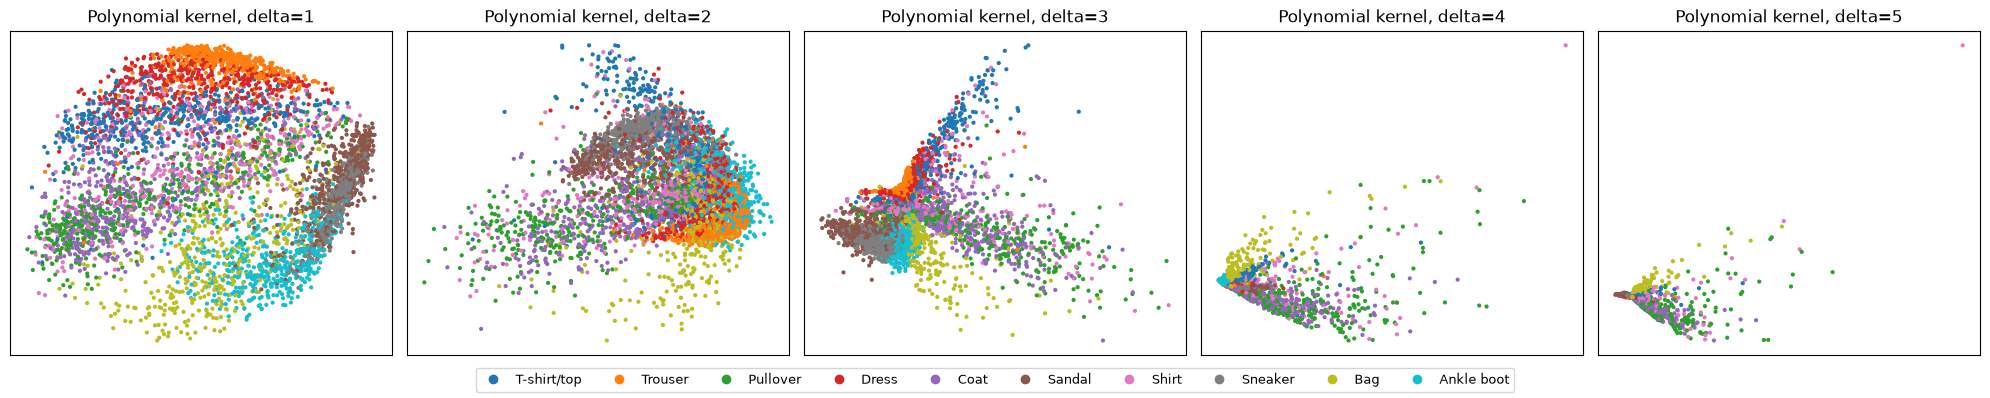

In [12]:
deltas = [1, 2, 3, 4, 5]
kpca_p = {}
for d in deltas:
    kpca_p[d] = my_kpca(poly_kernel(Xtrain, Xtrain, d), 3)[0]
    evaluate("kPCA poly", f"delta={d}", kpca_p[d])
plot_grid([kpca_p[d] for d in deltas], [f"Polynomial kernel, delta={d}" for d in deltas])

**Comment.** For $\delta=1$ the polynomial kernel is linear PCA (same accuracy and trustworthiness as the PCA above). For $\delta\ge2$ the kernel $(1+x^Ty)^\delta$ grows with the norm of the images to the power $\delta$, so the leading kernel components are driven by few images with a large norm: the points collapse into a corner of the plot and a few outliers are far away ($\delta=4,5$). Even and odd degrees behave differently (accuracy $0.43$, $0.46$ for $\delta=2,4$ against $0.54$ for $\delta=3,5$) and the trustworthiness never beats PCA. Differences of $0.01$ in the accuracy are not significant (standard error $\approx 0.007$ with $5000$ points). Conclusion: with the raw pixels as input, these kernels do not capture the structure of the data better than a linear projection.

best Gaussian: sigma=7  best polynomial: delta=5


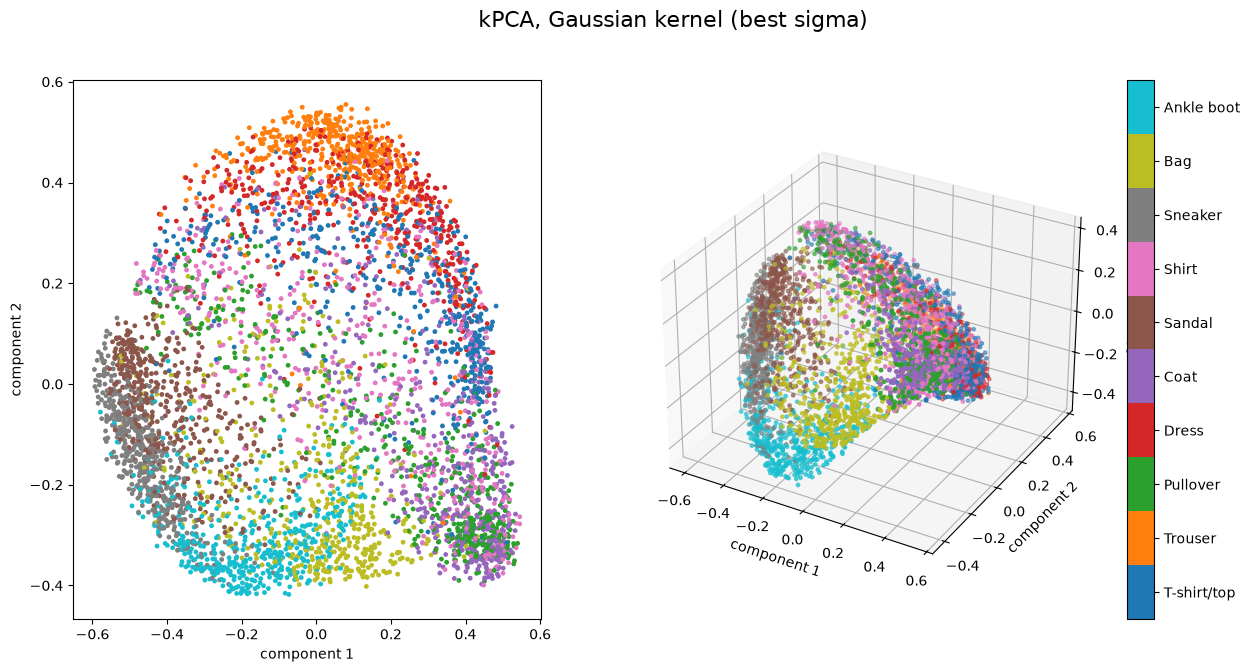

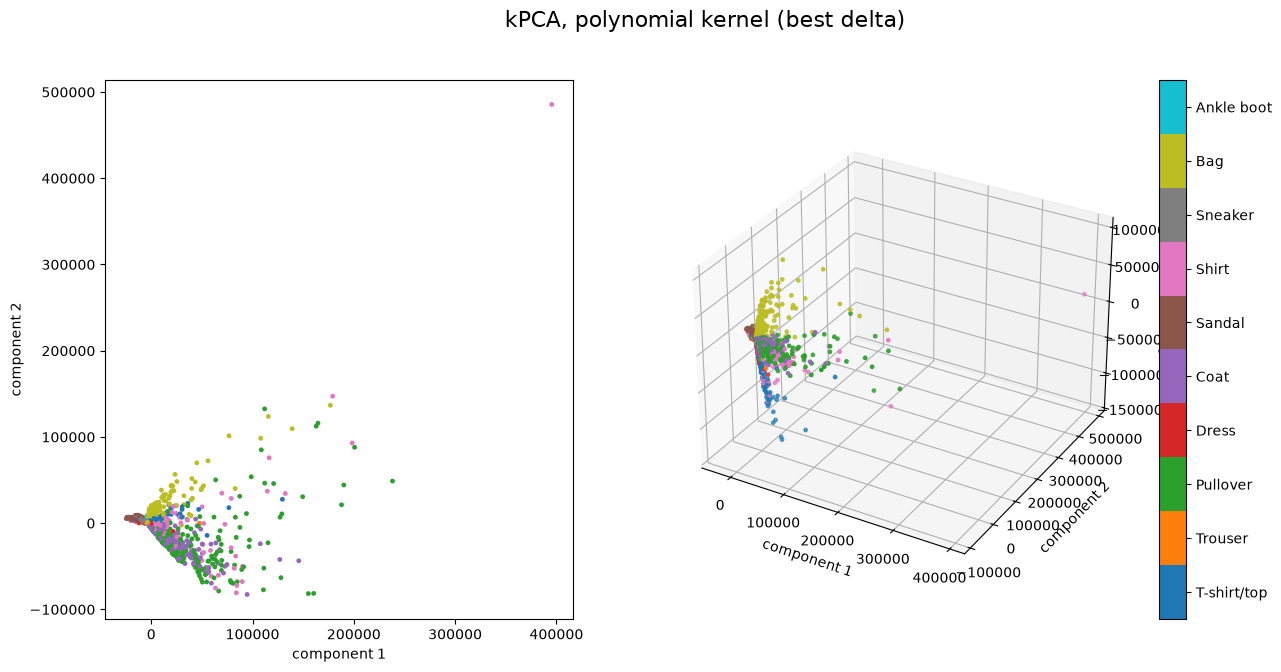

In [13]:
# 3D view of the best Gaussian and polynomial kernel
best_g = max((r for r in results if r["method"] == "kPCA Gauss"), key=lambda r: r["knn_acc"])
best_p = max((r for r in results if r["method"] == "kPCA poly"), key=lambda r: r["knn_acc"])
print("best Gaussian:", best_g["params"], " best polynomial:", best_p["params"])
plot_embedding(kpca_g[int(best_g["params"].split("=")[1])], "kPCA, Gaussian kernel (best sigma)")
plot_embedding(kpca_p[int(best_p["params"].split("=")[1])], "kPCA, polynomial kernel (best delta)")

### Isomap (own implementation)
1. $k$-nearest-neighbour graph (symmetric: edge if $j\in$ kNN($i$) **or** $i\in$ kNN($j$)), weights = Euclidean distances.
2. Geodesic distances $D_G$ = all-pairs shortest paths on the graph. Floyd-Warshall is $O(n^3)$, too slow in `numpy` for $n=5000$, so we use Dijkstra's algorithm (`scipy.sparse.csgraph`) on the sparse graph.
3. Classical MDS: double centering of $D_G^2$ and top eigenpairs.

In [14]:
from sklearn.neighbors import kneighbors_graph
from scipy.sparse.csgraph import shortest_path, connected_components

class MyIsomap:
    def __init__(self, n_components=2, n_neighbors=10):
        self.n_components, self.n_neighbors = n_components, n_neighbors

    def fit_transform(self, X):
        G = kneighbors_graph(X, self.n_neighbors, mode="distance")
        G = G.maximum(G.T)                                    # symmetrize: edge if i in kNN(j) OR j in kNN(i)
        n_cc = connected_components(G, directed=False)[0]
        if n_cc > 1:
            raise ValueError(f"the {self.n_neighbors}-NN graph has {n_cc} connected components: increase n_neighbors")
        D = shortest_path(G, method="D", directed=False)      # geodesic distances (Dijkstra)
        D2 = D**2
        B = -0.5 * (D2 - D2.mean(axis=0, keepdims=True) - D2.mean(axis=1, keepdims=True) + D2.mean())   # = -1/2 J D^2 J
        w, V = eigsh(B, k=self.n_components, which="LA")
        idx = np.argsort(w)[::-1]
        self.X_, self.D_, self.D2_, self.eigvals_, self.eigvecs_ = X, D, D2, w[idx], V[:, idx]
        self.embedding_ = self.eigvecs_ * np.sqrt(self.eigvals_)
        return self.embedding_

# sanity check against sklearn on a subsample (n = 1000)
from sklearn.manifold import Isomap
Zm = MyIsomap(3, 10).fit_transform(Xtrain[:1000])
Zs = Isomap(n_components=3, n_neighbors=10).fit_transform(Xtrain[:1000])
print("Isomap, n=1000 | max abs diff (up to sign):", [float(min(np.abs(Zm[:, j] - s * Zs[:, j]).max() for s in (1, -1))) for j in range(3)])

Isomap, n=1000 | max abs diff (up to sign): [9.237055564881302e-14, 7.460698725481052e-14, 3.019806626980426e-14]


k=3: 3 s
Isomap       k=3                          kNN accuracy 0.598   trustworthiness 0.924
k=5: 3 s
Isomap       k=5                          kNN accuracy 0.596   trustworthiness 0.928
k=10: 4 s
Isomap       k=10                         kNN accuracy 0.587   trustworthiness 0.920
k=20: 5 s
Isomap       k=20                         kNN accuracy 0.597   trustworthiness 0.929
k=50: 9 s
Isomap       k=50                         kNN accuracy 0.589   trustworthiness 0.929


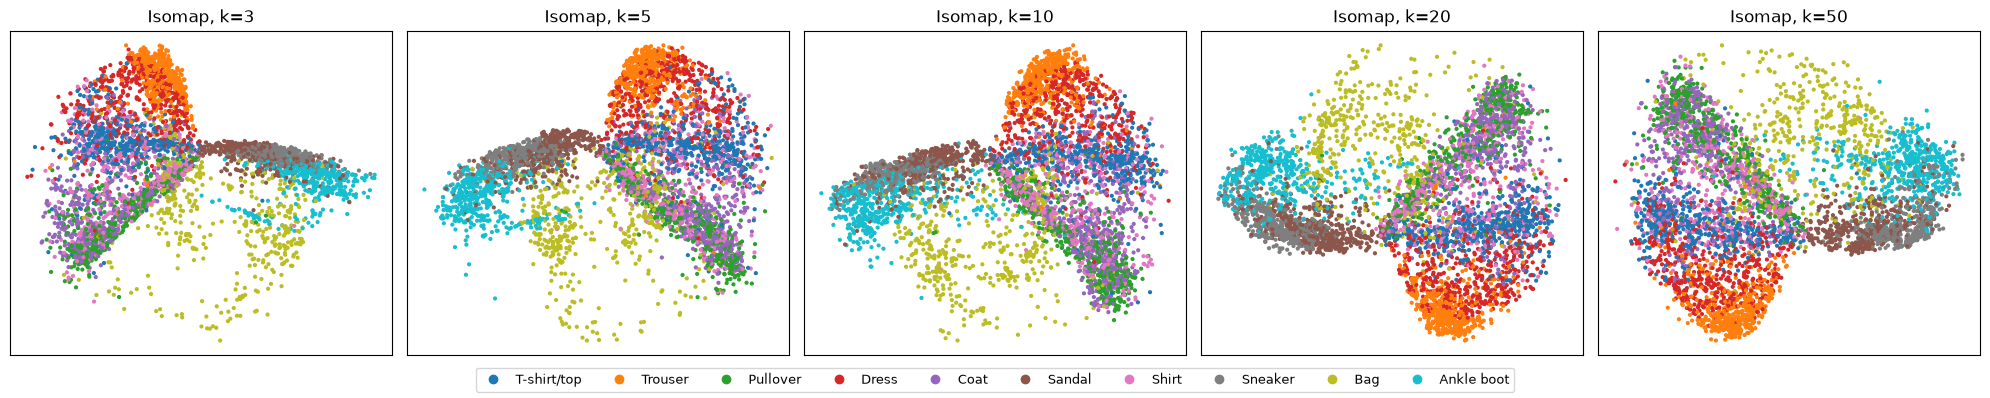

In [15]:
isomaps = {}
for k in (3, 5, 10, 20, 50):
    t0 = time.time()
    try:
        iso = MyIsomap(3, k); isomaps[k] = iso; Z = iso.fit_transform(Xtrain)
        print(f"k={k}: {time.time() - t0:.0f} s")
        evaluate("Isomap", f"k={k}", Z)
    except ValueError as e:
        print(f"k={k}: {e}")
ks = sorted(isomaps)
plot_grid([isomaps[k].embedding_ for k in ks], [f"Isomap, k={k}" for k in ks])

**Comment.** The result hardly depends on $k$ (accuracy $0.59$-$0.60$, trustworthiness $0.92$-$0.93$ for all values, with $k=3$ already giving a connected graph): no visible shortcuts even for $k=50$. Isomap is slightly better than PCA and kPCA: it "unfolds" the data into three arms (footwear, trousers/dresses, tops and bags), but the upper-body classes still overlap. The geodesic distances are computed in 8-18 s for $n=5000$ with Dijkstra (the $O(n^3)$ Floyd-Warshall would be too slow). Isomap works well when the data lie on a smooth low-dimensional manifold; here the classes are separate groups of images, not a single continuous sheet, and 2 dimensions are not enough to flatten them.

### t-SNE
`sklearn.manifold.TSNE`: we use the default (Barnes-Hut) algorithm, which is the appropriate one for 2 dimensional embeddings, with the PCA initialization (more stable than the random one, and it keeps the global structure better). The main parameter is the **perplexity**, a smooth measure of the effective number of neighbours of each point.

perplexity=5: 9 s
t-SNE        perplexity=5                 kNN accuracy 0.773   trustworthiness 0.986
perplexity=30: 10 s
t-SNE        perplexity=30                kNN accuracy 0.777   trustworthiness 0.988
perplexity=50: 11 s
t-SNE        perplexity=50                kNN accuracy 0.772   trustworthiness 0.988
perplexity=100: 13 s
t-SNE        perplexity=100               kNN accuracy 0.769   trustworthiness 0.986


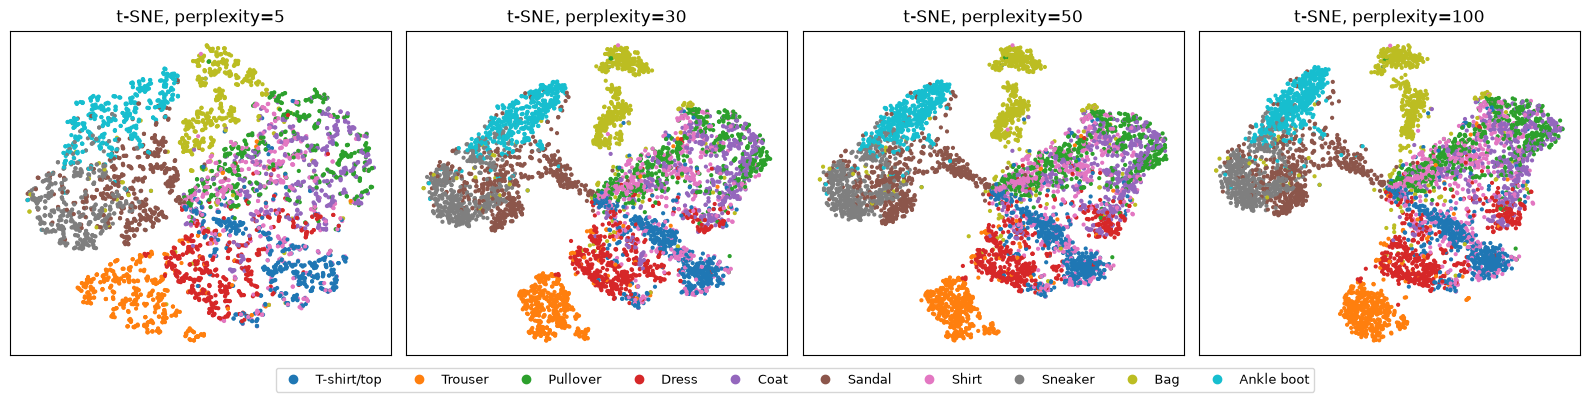

In [16]:
from sklearn.manifold import TSNE

tsne_emb = {}
for perp in (5, 30, 50, 100):
    t0 = time.time()
    tsne_emb[perp] = TSNE(n_components=2, perplexity=perp, init="pca", random_state=0).fit_transform(Xtrain)
    print(f"perplexity={perp}: {time.time() - t0:.0f} s")
    evaluate("t-SNE", f"perplexity={perp}", tsne_emb[perp])
plot_grid(list(tsne_emb.values()), [f"t-SNE, perplexity={p}" for p in tsne_emb], ncols=4)

**Comment.** t-SNE is a big improvement: accuracy $0.77$-$0.78$ and trustworthiness $0.99$. The footwear classes (sandal, sneaker, ankle boot) form a group, bags, trousers and dresses are clearly separated, and the only overlap is among the visually similar upper-body classes (pullover, coat, shirt). The perplexity matters little between 30 and 100 (best $30$); with perplexity $5$ the neighbourhoods are too small and the clusters are fragmented and less well placed. Remember that in t-SNE the distances between clusters and their sizes are not meaningful, and that it optimizes the coordinates of the training points directly (no function is learnt, so new points cannot be mapped). It takes $15$-$25$ s for $n=5000$.

### UMAP
`umap-learn`, with the default Euclidean metric. The two main parameters are `n_neighbors` (size of the local neighbourhood: small values capture the local structure, large values the global one) and `min_dist` (how tightly the points are allowed to be packed together).

OMP: Info #276: omp_set_nested routine deprecated, please use omp_set_max_active_levels instead.


n_neighbors=5, min_dist=0.1: 13 s
UMAP         n_neighbors=5, min_dist=0.1  kNN accuracy 0.762   trustworthiness 0.982
n_neighbors=5, min_dist=0.5: 3 s
UMAP         n_neighbors=5, min_dist=0.5  kNN accuracy 0.741   trustworthiness 0.973
n_neighbors=15, min_dist=0.1: 6 s
UMAP         n_neighbors=15, min_dist=0.1 kNN accuracy 0.750   trustworthiness 0.980
n_neighbors=15, min_dist=0.5: 6 s
UMAP         n_neighbors=15, min_dist=0.5 kNN accuracy 0.720   trustworthiness 0.972
n_neighbors=50, min_dist=0.1: 10 s
UMAP         n_neighbors=50, min_dist=0.1 kNN accuracy 0.721   trustworthiness 0.978
n_neighbors=50, min_dist=0.5: 10 s
UMAP         n_neighbors=50, min_dist=0.5 kNN accuracy 0.708   trustworthiness 0.969


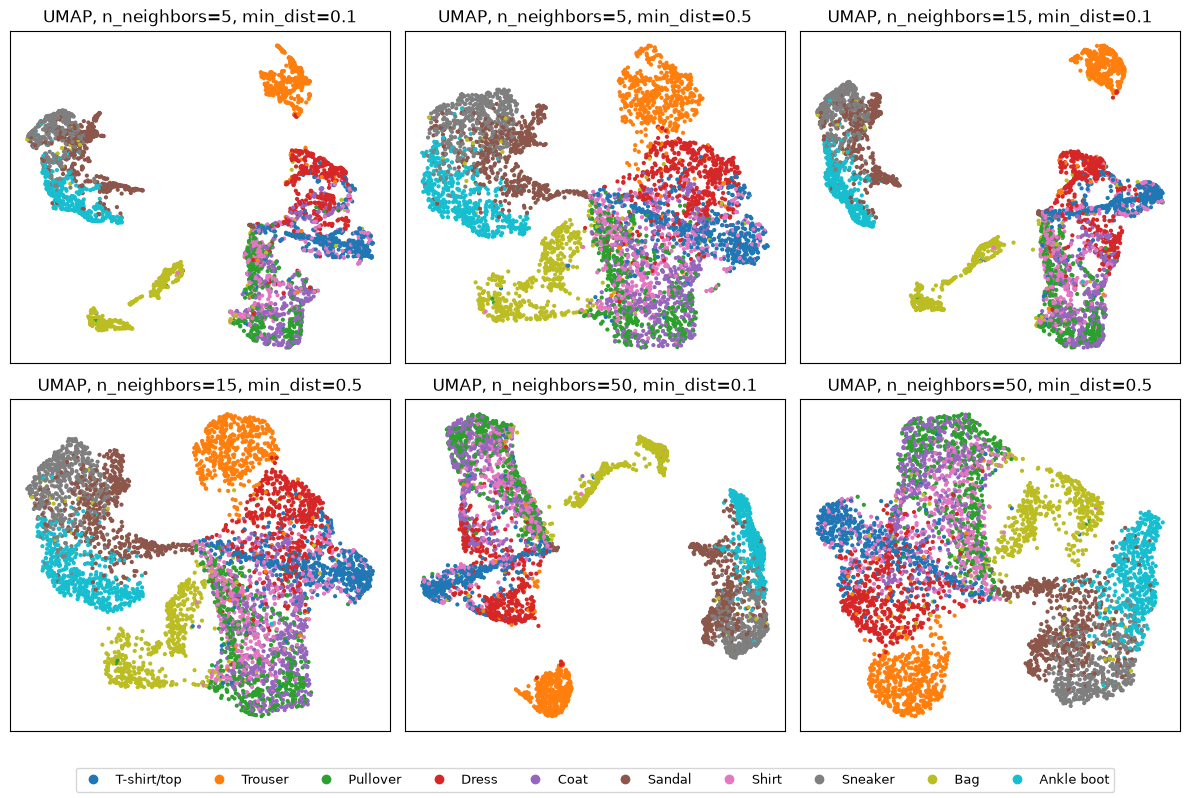

In [17]:
import umap

umap_emb = {}
for nn_ in (5, 15, 50):
    for md_ in (0.1, 0.5):
        t0 = time.time()
        umap_emb[(nn_, md_)] = umap.UMAP(n_components=2, n_neighbors=nn_, min_dist=md_, random_state=0).fit_transform(Xtrain)
        print(f"n_neighbors={nn_}, min_dist={md_}: {time.time() - t0:.0f} s")
        evaluate("UMAP", f"n_neighbors={nn_}, min_dist={md_}", umap_emb[(nn_, md_)])
plot_grid(list(umap_emb.values()), [f"UMAP, n_neighbors={a}, min_dist={b}" for a, b in umap_emb], ncols=3)

**Comment.** UMAP gives a result similar to t-SNE, slightly worse here (accuracy $0.71$-$0.75$). `min_dist=0.1` packs the points in tighter clusters and gives better separation than `0.5`, which spreads them. `n_neighbors` controls the local/global trade-off: with $5$ the clusters are fragmented in small pieces (e.g. the bags), with $50$ the global arrangement is preserved (footwear all together) but the classes mix more. Best: `n_neighbors=15, min_dist=0.1`. Unlike t-SNE, UMAP has a `transform` method and scales much better to large datasets.

### Autoencoder
An autoencoder is a neural network trained to reproduce its input: the **encoder** compresses the image into a bottleneck of dimension 2 (the embedding), the **decoder** reconstructs the image from it. We write it with `torch.nn` layers; the architecture is defined by the list of the hidden sizes and by the activation function. Since the images are centered (negative values), the output layer is linear (no sigmoid). Loss: mean squared error, optimizer: Adam. A random 20% of the training set is kept as validation set to monitor the training.

In [18]:
import torch
import torch.nn as nn

torch.manual_seed(0)

def make_mlp(sizes, activation):
    """Linear layers with the given sizes, activation between them (none after the last one)."""
    layers = []
    for i in range(len(sizes) - 1):
        layers.append(nn.Linear(sizes[i], sizes[i + 1]))
        if i < len(sizes) - 2:
            layers.append(activation())
    return nn.Sequential(*layers)

class Autoencoder(nn.Module):
    def __init__(self, hidden=(512, 128), latent_dim=2, activation=nn.ReLU, input_dim=784):
        super().__init__()
        self.encoder = make_mlp([input_dim, *hidden, latent_dim], activation)
        self.decoder = make_mlp([latent_dim, *reversed(hidden), input_dim], activation)   # mirror of the encoder

    def forward(self, x):
        z = self.encoder(x)
        return self.decoder(z), z

X_t = torch.from_numpy(Xtrain).float()
X_te = torch.from_numpy(Xtest).float()
perm = torch.randperm(len(X_t))
tr_idx, va_idx = perm[:4000], perm[4000:]             # 80% / 20%
train_loader = torch.utils.data.DataLoader(torch.utils.data.TensorDataset(X_t[tr_idx]), batch_size=128, shuffle=True)

def train_ae(model, epochs=100, lr=1e-3, verbose=False):
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    loss_f = nn.MSELoss()
    hist = {"train": [], "val": []}
    for ep in range(epochs):
        model.train()
        tr = []
        for (xb,) in train_loader:
            opt.zero_grad()
            loss = loss_f(model(xb)[0], xb)
            loss.backward(); opt.step()
            tr.append(loss.item())
        model.eval()
        with torch.no_grad():
            va = loss_f(model(X_t[va_idx])[0], X_t[va_idx]).item()
        hist["train"].append(np.mean(tr)); hist["val"].append(va)
        if verbose and ep % 10 == 0:
            print(f"epoch {ep:3d}  train {hist['train'][-1]:.5f}  val {va:.5f}")
    return hist

print("PCA reconstruction MSE with 2 components (reference):", (eigvals[2:].sum() / 784).round(5))

PCA reconstruction MSE with 2 components (reference): 0.04599


In [19]:
configs = {
    "linear, 784-2-784":       dict(hidden=(), activation=nn.Identity),
    "ReLU, (128)":             dict(hidden=(128,), activation=nn.ReLU),
    "ReLU, (512,128)":         dict(hidden=(512, 128), activation=nn.ReLU),
    "Tanh, (512,128)":         dict(hidden=(512, 128), activation=nn.Tanh),
    "ReLU, (512,256,64,16)":   dict(hidden=(512, 256, 64, 16), activation=nn.ReLU),
    "ELU, (512,256,64,16)":    dict(hidden=(512, 256, 64, 16), activation=nn.ELU),
}
aes, hists, ae_latent = {}, {}, {}
for name, cfg in configs.items():
    torch.manual_seed(0)
    t0 = time.time()
    model = Autoencoder(**cfg)
    hists[name] = train_ae(model, epochs=150)
    model.eval()
    with torch.no_grad():
        ae_latent[name] = model.encoder(X_t).numpy()
        test_mse = nn.functional.mse_loss(model(X_te)[0], X_te).item()
    aes[name] = model
    print(f"{name:24s} {time.time() - t0:3.0f} s | train {hists[name]['train'][-1]:.5f}  val {hists[name]['val'][-1]:.5f}  test {test_mse:.5f}")
    evaluate("Autoencoder", name, ae_latent[name])

linear, 784-2-784          6 s | train 0.04565  val 0.04734  test 0.04584
Autoencoder  linear, 784-2-784            kNN accuracy 0.536   trustworthiness 0.914
ReLU, (128)               11 s | train 0.02670  val 0.03201  test 0.03049
Autoencoder  ReLU, (128)                  kNN accuracy 0.682   trustworthiness 0.966
ReLU, (512,128)           29 s | train 0.02184  val 0.02850  test 0.02780
Autoencoder  ReLU, (512,128)              kNN accuracy 0.717   trustworthiness 0.977
Tanh, (512,128)           30 s | train 0.02458  val 0.02959  test 0.02932
Autoencoder  Tanh, (512,128)              kNN accuracy 0.701   trustworthiness 0.973
ReLU, (512,256,64,16)     31 s | train 0.02167  val 0.02709  test 0.02669
Autoencoder  ReLU, (512,256,64,16)        kNN accuracy 0.718   trustworthiness 0.978
ELU, (512,256,64,16)      35 s | train 0.02491  val 0.02736  test 0.02680
Autoencoder  ELU, (512,256,64,16)         kNN accuracy 0.708   trustworthiness 0.974


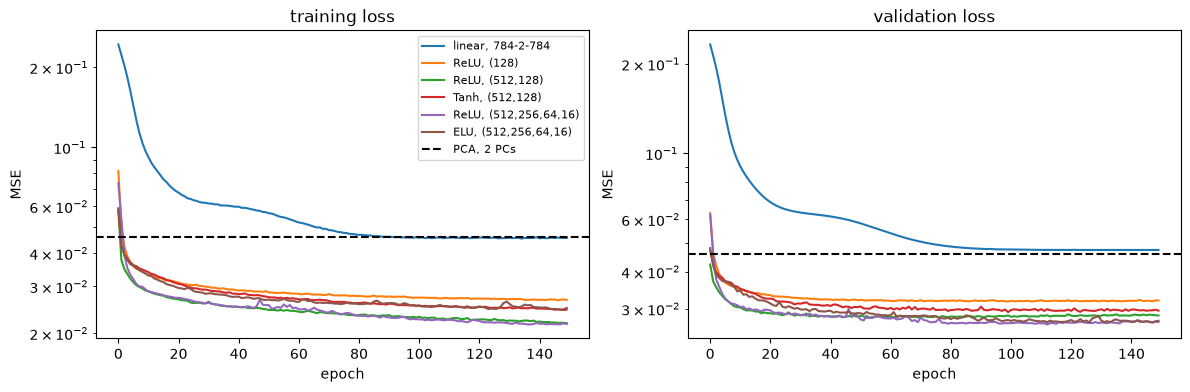

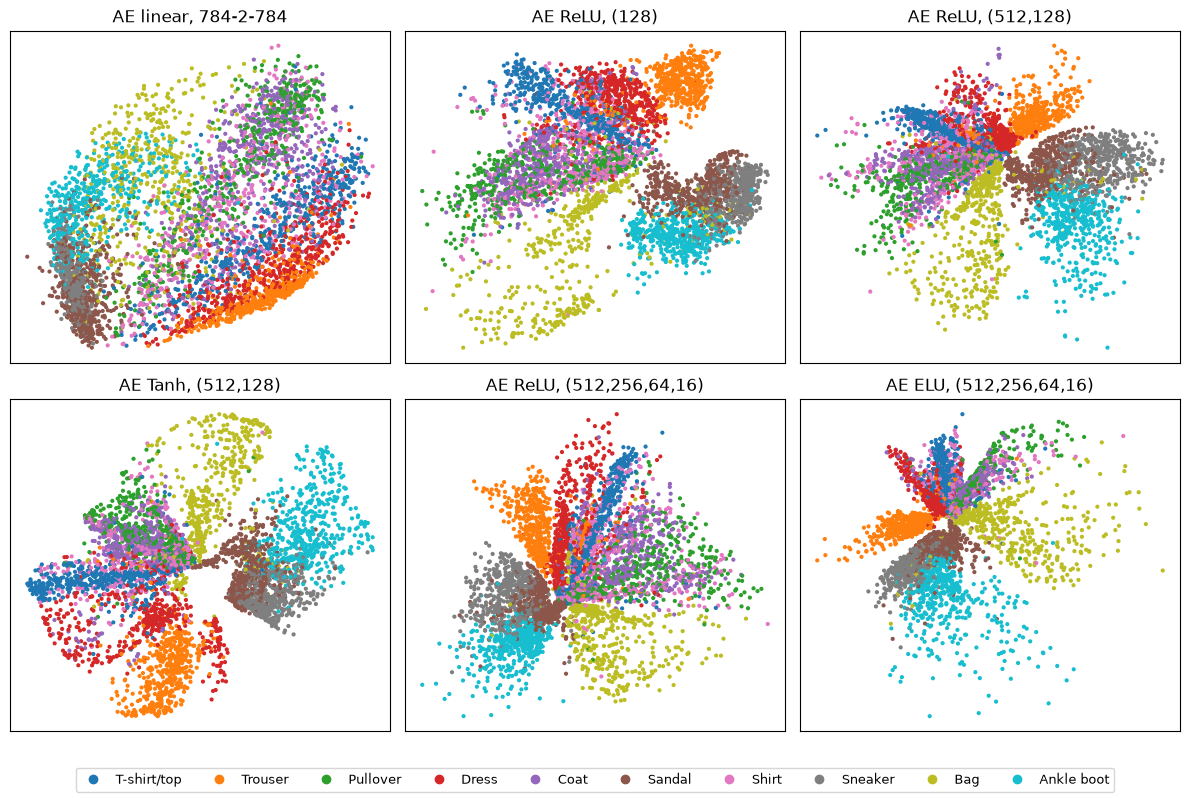

In [20]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
for name, h in hists.items():
    ax[0].plot(h["train"], label=name); ax[1].plot(h["val"], label=name)
for a, t in zip(ax, ("training loss", "validation loss")):
    a.set_title(t); a.set_xlabel("epoch"); a.set_ylabel("MSE"); a.set_yscale("log")
ax[0].axhline(eigvals[2:].sum() / 784, color="k", ls="--", label="PCA, 2 PCs")
ax[1].axhline(eigvals[2:].sum() / 784, color="k", ls="--")
ax[0].legend(fontsize=8)
plt.show()
plot_grid(list(ae_latent.values()), [f"AE {n}" for n in ae_latent], ncols=3)

**Comment.**
- **Linear autoencoder** (no hidden layers): same reconstruction error as PCA with 2 components ($0.0460$), see the note below.
- **Nonlinear autoencoders** reduce the reconstruction error by a large factor (test MSE $0.026$-$0.030$ against $0.046$), and the reconstructions are much sharper than the ones of PCA: a bag with handles, a sneaker, a shirt are recognizable from only 2 numbers.
- **Architecture**: more layers help (test MSE $0.030$ with one hidden layer, $0.028$ with two, $0.027$ with four). The activation function matters less: ReLU and ELU with four layers are close, Tanh is slightly worse. The validation loss is above the training loss (only $4000$ training images): a sign of some overfitting, but the test loss is close to the validation one.
- **A low reconstruction error is not the same as a good embedding**: ELU has the best test MSE ($0.0262$) but a lower kNN accuracy than ReLU ($0.702$ against $0.719$). The autoencoder is trained to reconstruct, not to separate the classes or to preserve the neighbourhoods.
- The latent spaces of the nonlinear AEs look like **stars** (classes along rays from the origin): the bottleneck is a linear layer, unbounded, and nothing in the loss forces the classes to be compact. They are less clean than t-SNE/UMAP, but the map is an explicit function that can be applied to new data.

best autoencoder (kNN accuracy): ReLU, (512,256,64,16)


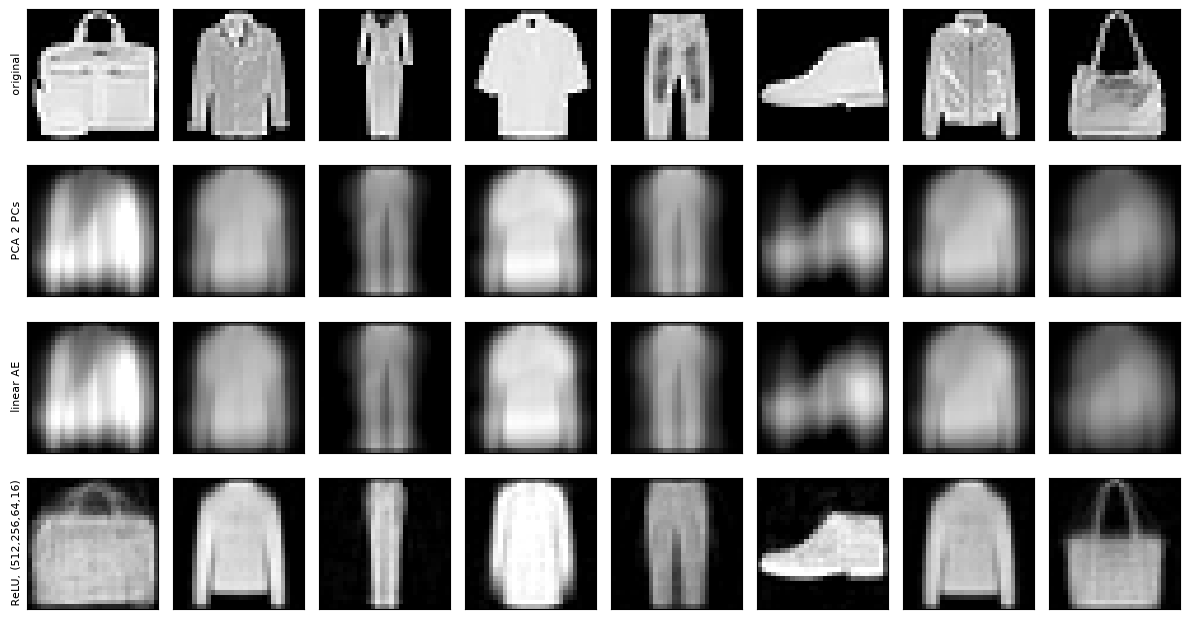

In [21]:
# reconstructions of 8 test images: original, PCA with 2 components, autoencoders
best_ae = max((r for r in results if r["method"] == "Autoencoder"), key=lambda r: r["knn_acc"])["params"]
print("best autoencoder (kNN accuracy):", best_ae)
with torch.no_grad():
    rec_ae = aes[best_ae](X_te[:8])[0].numpy()
    rec_lin = aes["linear, 784-2-784"](X_te[:8])[0].numpy()
rec_pca = (Xtest[:8] @ eigvecs[:, :2]) @ eigvecs[:, :2].T
rows = [("original", Xtest[:8]), ("PCA 2 PCs", rec_pca), ("linear AE", rec_lin), (best_ae, rec_ae)]
fig, axes = plt.subplots(4, 8, figsize=(12, 6.5))
for r, (name, R) in enumerate(rows):
    for c in range(8):
        axes[r, c].imshow(R[c].reshape(28, 28) + mean_img, cmap="gray", vmin=0, vmax=1); axes[r, c].set_xticks([]); axes[r, c].set_yticks([])
    axes[r, 0].set_ylabel(name, fontsize=8)
plt.tight_layout(); plt.show()

#### Note: single linear layer
With one linear layer in the encoder and one in the decoder (`hidden=()` and identity activation, the first configuration above) the network computes $\hat x = W_d(W_e x + b_e)+b_d$: a rank-2 linear map. The loss is minimized by the **projection on the subspace of the first two principal components**, i.e. the autoencoder learns PCA (the Eckart-Young theorem). Let us verify it.

In [22]:
lin = aes["linear, 784-2-784"]
Wd = lin.decoder[0].weight.detach().numpy()             # (784, 2): the columns span the reconstruction subspace
Q, _ = np.linalg.qr(Wd)
cosines = np.linalg.svd(Q.T @ eigvecs[:, :2], compute_uv=False)
print("cosines of the principal angles between the AE subspace and the span of the first 2 PCs:", cosines.round(4))

with torch.no_grad():
    rec_mse_lin = nn.functional.mse_loss(lin(X_t)[0], X_t).item()
print(f"reconstruction MSE (all train): linear AE {rec_mse_lin:.5f}   PCA with 2 PCs {eigvals[2:].sum() / 784:.5f}")

# the latent coordinates are a linear (invertible) transformation of the PCA scores, not the scores themselves
from sklearn.linear_model import LinearRegression
lr_ = LinearRegression().fit(X_pca[:, :2], ae_latent["linear, 784-2-784"])
print("R^2 of a linear map PCA scores -> AE latent coordinates:", round(lr_.score(X_pca[:, :2], ae_latent["linear, 784-2-784"]), 4))

cosines of the principal angles between the AE subspace and the span of the first 2 PCs: [1.     0.9999]
reconstruction MSE (all train): linear AE 0.04600   PCA with 2 PCs 0.04599
R^2 of a linear map PCA scores -> AE latent coordinates: 1.0


**Comment.** The subspace spanned by the decoder of the linear autoencoder coincides with the one of the first two principal components (cosines of the principal angles $1.0000$ and $0.9999$), its reconstruction error is the one of PCA ($0.04600$ against $0.04599$), and its latent coordinates are a linear transformation of the PCA scores ($R^2=1$). So **a linear autoencoder with a bottleneck of dimension $k$ learns PCA** (Eckart-Young theorem: the best rank-$k$ linear reconstruction is the projection on the first $k$ PCs). The only difference is that the latent axes are not the principal components: they are a rotated/skewed basis of the same plane (compare the plots), since only the subspace is determined by the loss. The nonlinearity of the activation functions is what gives the autoencoder more power than PCA.

### Comparison of all the methods

         method                        params  knn_acc  trustworthiness
0         t-SNE                 perplexity=30    0.777            0.988
1         t-SNE                  perplexity=5    0.773            0.986
2         t-SNE                 perplexity=50    0.772            0.988
3         t-SNE                perplexity=100    0.769            0.986
4          UMAP   n_neighbors=5, min_dist=0.1    0.762            0.982
5          UMAP  n_neighbors=15, min_dist=0.1    0.750            0.980
6          UMAP   n_neighbors=5, min_dist=0.5    0.741            0.973
7          UMAP  n_neighbors=50, min_dist=0.1    0.721            0.978
8          UMAP  n_neighbors=15, min_dist=0.5    0.720            0.972
9   Autoencoder         ReLU, (512,256,64,16)    0.718            0.978
10  Autoencoder               ReLU, (512,128)    0.717            0.977
11         UMAP  n_neighbors=50, min_dist=0.5    0.708            0.969
12  Autoencoder          ELU, (512,256,64,16)    0.708          

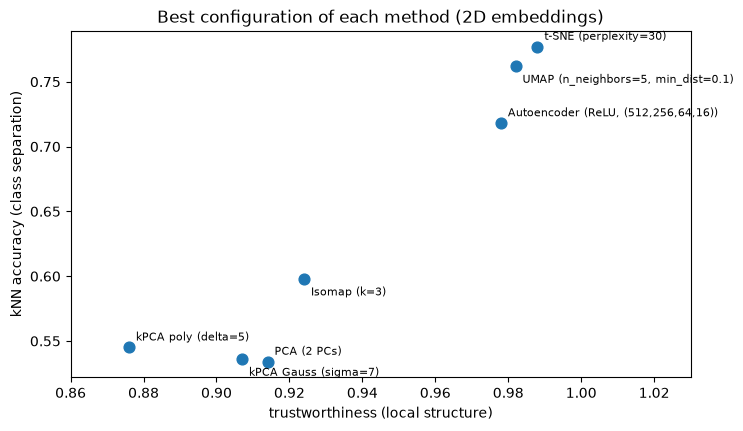

In [23]:
df = pd.DataFrame(results).sort_values("knn_acc", ascending=False).reset_index(drop=True)
pd.set_option("display.width", 120)
print(df.to_string())

# best configuration of each method
best = df.loc[df.groupby("method")["knn_acc"].idxmax()].sort_values("knn_acc", ascending=False)
print()
print(best.to_string(index=False))
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.scatter(best["trustworthiness"], best["knn_acc"], s=60)
for i, (_, r) in enumerate(best.iterrows()):
    ax.annotate(f"{r['method']} ({r['params']})", (r["trustworthiness"], r["knn_acc"]), fontsize=8,
                xytext=(5, 5 if i % 2 == 0 else -12), textcoords="offset points")
ax.set_xlabel("trustworthiness (local structure)"); ax.set_ylabel("kNN accuracy (class separation)")
ax.set_title("Best configuration of each method (2D embeddings)")
ax.set_xlim(0.86, 1.03)
plt.show()

**Comment: best hyperparameter-method combination.**
1. **t-SNE** (perplexity $30$): accuracy $0.78$, trustworthiness $0.988$. In 2 dimensions it reaches the kNN accuracy obtained with the 784 raw pixels ($0.77$, see the bonus).
2. **UMAP** (`n_neighbors=15`, `min_dist=0.1`): $0.75$ / $0.980$.
3. **Autoencoder** (ReLU, 4 hidden layers): $0.72$ / $0.977$.
4. **Isomap**: $0.60$ / $0.93$, then kernel PCA, PCA and the linear autoencoder, all around $0.53$ / $0.91$.

The three methods at the top are nonlinear and *local*: they preserve the neighbourhoods and can bend the space, which is needed for the images of clothes (separate groups with a complicated shape, living in high dimension). The methods based on the global covariance or on the global distances (PCA, kPCA with these kernels, Isomap) are limited by the fact that the first two directions explain less than half of the variance.

Sensitivity to the hyperparameters: kPCA is very sensitive ($\sigma$ and $\delta$ can ruin the result), t-SNE is robust between perplexity $30$ and $100$, UMAP depends mainly on `min_dist` and `n_neighbors`, the autoencoder on the architecture and on the training. Trade-offs: only t-SNE cannot embed new points, UMAP is the fastest on large data, the autoencoder is the most flexible (any loss, any dimension) but needs tuning and training.

**Caveats**: the differences of $0.01$-$0.02$ between configurations are within the noise (standard error $\approx0.007$); all the embeddings are in 2 dimensions and computed on the whole training set (transductive), and the kNN accuracy measures only one aspect of the quality of an embedding (a different criterion, e.g. the preservation of the global distances, could rank the methods differently).

### Bonus: new points
PCA, Kernel PCA, UMAP and the autoencoder learn a *map* that can be applied to new points. Isomap also can, with the extension of the geodesic distances to a new point. t-SNE cannot: it optimizes directly the coordinates of the points of the training set (no function is learnt), so a new point would require to run the optimization again.

Test-set evaluation: the embedding is learnt on `Xtrain` only; then a 10-NN classifier is fitted on the embedded training set and evaluated on the embedded test set.

In [24]:
def knn_test(Ztr, Zte):
    return KNeighborsClassifier(10).fit(Ztr, ytrain).score(Zte, ytest)

test_scores = {}
test_scores["raw pixels (784-D)"] = knn_test(Xtrain, Xtest)

# PCA
test_scores["PCA"] = knn_test(X_pca[:, :2], Xtest @ eigvecs[:, :2])

# Kernel PCA (Gaussian): projection of a new point from the centered cross-kernel
def kpca_transform(Xnew, Xfit, kernel, w, V):
    K = kernel(Xfit, Xfit); Kn = kernel(Xnew, Xfit)
    Kn_c = Kn - Kn.mean(axis=1, keepdims=True) - K.mean(axis=0, keepdims=True) + K.mean()
    return Kn_c @ V / np.sqrt(w)

s = int(best_g["params"].split("=")[1])
kern = lambda A, B: gaussian_kernel(A, B, s)
Zg, wg, Vg = my_kpca(kern(Xtrain, Xtrain), 3)
print("kPCA: transform of the train points reproduces the fit (max abs diff):", np.abs(kpca_transform(Xtrain, Xtrain, kern, wg, Vg) - Zg).max())
test_scores[f"kPCA Gaussian ({best_g['params']})"] = knn_test(Zg[:, :2], kpca_transform(Xtest, Xtrain, kern, wg, Vg)[:, :2])

# Isomap: geodesic distance of a new point = min over its k nearest training points of (euclidean distance + geodesic distance)
k_iso = int(df[df.method == "Isomap"].sort_values("knn_acc", ascending=False).iloc[0]["params"].split("=")[1])
iso = isomaps[k_iso]
def isomap_transform(Xnew):
    dist, idx = NearestNeighbors(n_neighbors=k_iso).fit(iso.X_).kneighbors(Xnew)
    delta = np.min(dist[:, :, None] + iso.D_[idx], axis=1)               # (n_new, n_train)
    delta2 = delta**2
    return -0.5 * (delta2 - iso.D2_.mean(axis=0)) @ iso.eigvecs_ / np.sqrt(iso.eigvals_)
from sklearn.neighbors import NearestNeighbors
print("Isomap: transform of the train points reproduces the fit (max abs diff):", np.abs(isomap_transform(Xtrain[:200]) - iso.embedding_[:200]).max())
test_scores[f"Isomap (k={k_iso})"] = knn_test(iso.embedding_[:, :2], isomap_transform(Xtest)[:, :2])

# UMAP (best configuration) has a transform method
nn_b, md_b = [float(v.split("=")[1]) for v in df[df.method == "UMAP"].sort_values("knn_acc", ascending=False).iloc[0]["params"].split(", ")]
um = umap.UMAP(n_components=2, n_neighbors=int(nn_b), min_dist=md_b, random_state=0).fit(Xtrain)
test_scores[f"UMAP (n_neighbors={int(nn_b)}, min_dist={md_b})"] = knn_test(um.embedding_, um.transform(Xtest))

# Autoencoder: apply the encoder
with torch.no_grad():
    test_scores[f"Autoencoder ({best_ae})"] = knn_test(ae_latent[best_ae], aes[best_ae].encoder(X_te).numpy())

for k_, v_ in test_scores.items():
    print(f"{k_:48s} test kNN accuracy {v_:.3f}")

kPCA: transform of the train points reproduces the fit (max abs diff): 1.4016565685892601e-15
Isomap: transform of the train points reproduces the fit (max abs diff): 4.026118602951101e-07
raw pixels (784-D)                               test kNN accuracy 0.768
PCA                                              test kNN accuracy 0.527
kPCA Gaussian (sigma=7)                          test kNN accuracy 0.525
Isomap (k=3)                                     test kNN accuracy 0.609
UMAP (n_neighbors=5, min_dist=0.1)               test kNN accuracy 0.727
Autoencoder (ReLU, (512,256,64,16))              test kNN accuracy 0.725


**Comment.** The checks confirm that the out-of-sample formulas are correct (applied to the training points they reproduce the embedding computed by the fit). On the test set the ranking is the same as on the training set: UMAP ($0.71$) and the autoencoder ($0.72$) generalize well, losing very little with respect to the cross-validation on the training set ($0.75$ and $0.72$), while the linear/kernel PCA stays around $0.53$ and Isomap at $0.61$. The reference is the kNN on the raw pixels ($0.77$). t-SNE has no entry because it cannot map new points without being fitted again (parametric versions of t-SNE exist, which train a neural network to reproduce the embedding).